# Introduction

In this tutorial, we demonstrate how to use **SpatialZoomer** to identify multi-scale spatial structures in single-cell resolved spatial transcriptomics (ST) data, ranging from cells to niches and tissue domains.  

For illustration, we use a Vizgen MERFISH mouse brain sample (83,546 cells, 483 genes). The tutorial can be completed on a standard personal computer in approximately 10–20 minutes.

#### Table of Contents
- [0. Installation, package loading, and data preprocessing](#0-installation-package-loading-and-data-preprocessing)
- [1. Extract multi-scale features via spectral graph signal processing](#1-extract-multi-scale-features-via-spectral-graph-signal-processing)
- [2. Identify critical scales automatically](#2-identify-critical-scales-automatically)
- [3. Identify spatial structures using two-step clustering](#3-identify-spatial-structures-using-two-step-clustering)
  - [Results and Analysis](#results-and-analysis)
  - [Results in the save_path Folder](#results-in-the-save_path-folder)
- [4. Scale-to-distance mapping](#4-scale-to-distance-mapping)

### 0. Installation, package loading, and data preprocessing

For detailed installation instructions, environment setup, and package dependencies, please refer to the [SpatialZoomer GitHub repository](https://github.com/Li-Xinqi/SpatialZoomer.git).

Install or upgrade to the latest version of SpatialZoomer:

```bash
python -m pip install --upgrade spatialzoomer
```

Import the installed package:

```python
import spatialzoomer as sz
```

Next, load the spatial transcriptomics data, perform cell- and gene-level quality control, and normalize the expression matrix.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Load packages
import spatialzoomer as sz
import numpy as np
import scanpy as sc
import seaborn as sns
import os
import matplotlib.pyplot as plt

# Set figure parameters
plt.rcParams.update({
    "font.family":'sans-serif',
    "mathtext.fontset":'stix',
    "font.size": 7,
    'pdf.fonttype': 42,
    "figure.dpi": 80,      
    "savefig.dpi": 300     
    })
use_dpi = 80 

Please set the following basic information:
* `runLabel`: The name of the dataset.

* `save_path`: A path to save the analysis results.

* `adata`: An **AnnData** object storing single-cell resolved spatial transcriptomics data,  

  - `adata.X` contains the raw, unnormalized transcript count matrix.  
  
  - `adata.obsm['spatial']` stores the spatial coordinates.  
 
The **input ST data** in AnnData format are available in the current Zenodo archive and can also be downloaded from [Google Drive](https://drive.google.com/file/d/1vdGMITckU3oX-yLJTIYPCcjoSJRSEkrg/view?usp=drive_link).

The original data can be downloaded from [Vizgen MERFISH Mouse Brain dataset - Slice2 Replicate1](https://info.vizgen.com/mouse-brain-map).  

In [2]:
runLabel = 'Vizgen_MERFISH_Brain_Slice2_Replicate1'
save_path = './Outputs/' + runLabel+'_SpatialZoomer/'
if not os.path.exists(save_path):
    os.makedirs(save_path)
adata = sc.read_h5ad("./" + runLabel+ "_anndata.h5ad")
adata

AnnData object with n_obs × n_vars = 83546 × 483
    obs: 'fov', 'volume', 'min_x', 'max_x', 'min_y', 'max_y', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_300_genes', 'n_counts', 'n_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'spatial'
    obsm: 'blank_genes', 'spatial', 'spatial_raw'

<Axes: title={'center': 'Volume of segmented cells'}, xlabel='volume', ylabel='Count'>

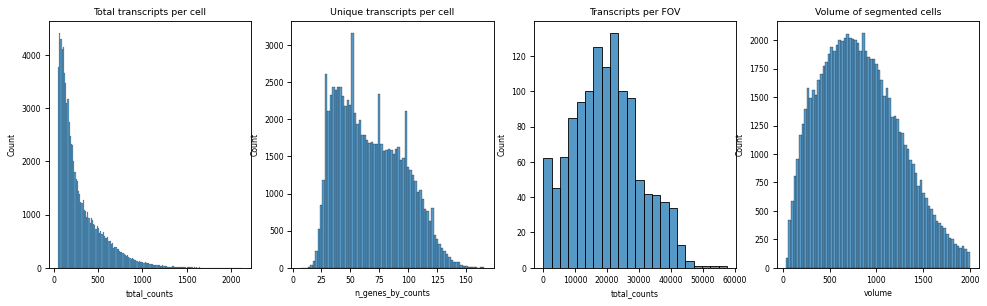

In [3]:
sc.pp.calculate_qc_metrics(adata, percent_top=(50, 100, 200, 300), inplace=True)
fig, axs = plt.subplots(1, 4, figsize=(15, 4), dpi=use_dpi)

axs[0].set_title("Total transcripts per cell")
sns.histplot(
    adata.obs["total_counts"],
    kde=False,
    ax=axs[0],
)

axs[1].set_title("Unique transcripts per cell")
sns.histplot(
    adata.obs["n_genes_by_counts"],
    kde=False,
    ax=axs[1],
)

axs[2].set_title("Transcripts per FOV")
sns.histplot(
    adata.obs.groupby("fov").sum()["total_counts"],
    kde=False,
    ax=axs[2],
)

axs[3].set_title("Volume of segmented cells")
sns.histplot(
    adata.obs["volume"],
    kde=False,
    ax=axs[3],
)

**Quality control and normalization**

* `filter_cells` removes low-quality cells with insufficient transcript and gene detection;
* `filter_genes` removes genes detected in too few cells;
* `sz.Preprocess` stores the original count matrix in `adata.layers["counts"]`, performs total-count normalization, and applies a log(1+x) transformation.

In [4]:
# Quality control on cells
sc.pp.filter_cells(adata, min_counts = 5)
sc.pp.filter_cells(adata, min_genes = 5)

# Quality control on genes
sc.pp.filter_genes(adata, min_cells = 5)

# Normalization
adata = sz.Preprocess(adata)
adata

AnnData object with n_obs × n_vars = 83546 × 483
    obs: 'fov', 'volume', 'min_x', 'max_x', 'min_y', 'max_y', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_300_genes', 'n_counts', 'n_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'spatial', 'log1p'
    obsm: 'blank_genes', 'spatial', 'spatial_raw'
    layers: 'counts'

### 1. Extract multi-scale features via spectral graph signal processing

- Obtain **graph signals** (cell programs) from transcriptomic data using dimensionality reduction with **NMF**.  

- Construct a **spatial neighbor graph** based on the physical proximity of cells.  

- Apply a bank of **heat kernel–based low-pass filters** to extract features across multiple spatial scales.

Perform NMF to obtain graph signals:

`n_components` specifies the dimensionality of the graph signals.

In [5]:
adata = sz.performDR(adata, type = 'NMF', n_components=50)
adata

Time taken to perform NMF: 78.2292 seconds


AnnData object with n_obs × n_vars = 83546 × 483
    obs: 'fov', 'volume', 'min_x', 'max_x', 'min_y', 'max_y', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_300_genes', 'n_counts', 'n_genes'
    var: 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'spatial', 'log1p'
    obsm: 'blank_genes', 'spatial', 'spatial_raw', 'X_nmf'
    varm: 'nmf_loadings'
    layers: 'counts'

Initialize the SpatialZoomer object and define a set of candidate scales.

In [6]:
sz_analyzer = sz.MultiscaleAnalysis(adata=adata, runLabel=runLabel, save_path=save_path)
 
scales = [0.01] \
    + np.arange(0.1, 2.1, 0.1).tolist() \
    + np.arange(2.5, 15.5, 0.5).tolist() \
    + np.arange(16, 21, 1).tolist() \
    +  np.arange(25, 55, 5).tolist()
scales = [round(x, 2) for x in scales]

In [7]:
# Set the image resolution to prevent the notebook from becoming too large.
sz_analyzer.dpi = use_dpi

Perform spectral graph signal processing to extract multi-scale features:

- `use_rep`: selects graph signals from adata.obsm; here we use "X_nmf" (NMF-transformed data)

- `n_neighbors`: number of neighbors in the spatial neighbor graph (recommended: 10–20)

- `scales`: custom-defined above; if not provided, scales are automatically generated as above

In [8]:
sz_analyzer.multiscale_transform(use_rep='X_nmf', n_neighbors=20, scales=scales)

Median similarities:  4.999999999987686
Time taken to construct spatial_knn: 0.6132 seconds
Time taken to perform spectral graph filter bank: 47.7185 seconds
Transformed signals saved to ./Outputs/Vizgen_MERFISH_Brain_Slice2_Replicate1_SpatialZoomer//Vizgen_MERFISH_Brain_Slice2_Replicate1_transformed_signals.h5


### 2. Identify critical scales automatically

SpatialZoomer employs a dynamic programming strategy that partitions the cross-scale similarity map, which is constructed from transformed signals across ranked candidate scales, into contiguous diagonal blocks. The optimal number of blocks is determined automatically. From each block, the start and center points are selected as critical scales, representing “tipping” and “representative” points, respectively. 

- `max_clusters` and `min_clusters` specify the range of possible block numbers.  
  Within this range, the Elbow method is applied to automatically determine the optimal number of blocks.

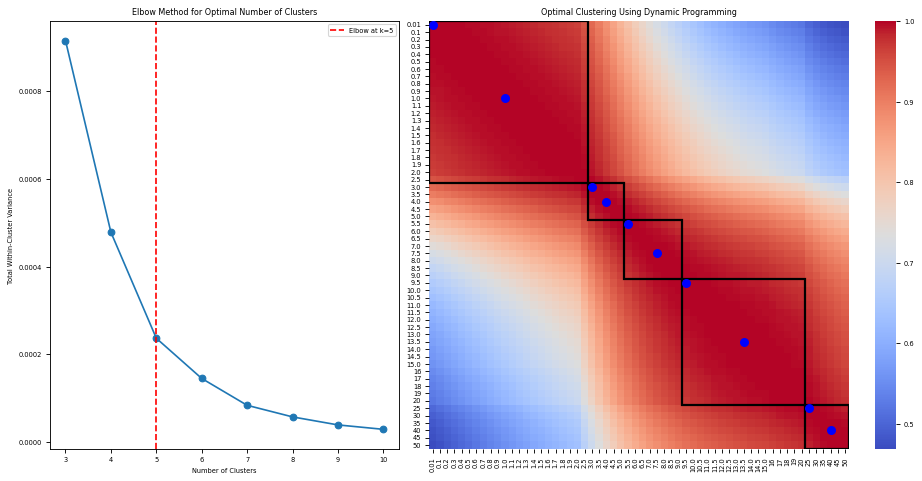

The optimal number of clusters is: 5
Typical scales: [0.01, 1.0, 3.0, 4.0, 5.5, 7.5, 9.5, 13.5, 25, 40]
Time taken to perform identification of typical scales: 8.7200 seconds


In [9]:
sz_analyzer.identify_typical_scales(max_clusters=10, min_clusters=3)

### 3. Identify spatial structures using two-step clustering

Clustering is performed in two steps:  

1. **Mini-Batch K-Means** is applied to the transformed signals at a given scale to obtain an initial coarse clustering, yielding 10,000 metacells.  

2. **Leiden algorithm** is then applied to the metacells to obtain fine-grained clusters. A higher clustering resolution yields more clusters.  

**Recommendation:** test **multiple resolution values** (e.g., 0.2, 0.4, 0.8, 1.0) and select the setting that matches biological expectations and downstream tasks.


In [10]:
resolutions = [0.8, 1]
sz_analyzer.clustering(n_clusters_kmeans=10000, resolutions=resolutions, max_scale = 30, min_scale = 0.5)

Time taken to perform UMAP and clustering for raw signal: 204.8549 seconds
Time taken to perform clustering for signal at scale 1.0: 78.5513 seconds
Time taken to perform clustering for signal at scale 3.0: 83.4878 seconds
Time taken to perform clustering for signal at scale 4.0: 68.8591 seconds
Time taken to perform clustering for signal at scale 5.5: 77.2838 seconds
Time taken to perform clustering for signal at scale 7.5: 73.2953 seconds
Time taken to perform clustering for signal at scale 9.5: 73.7299 seconds
Time taken to perform clustering for signal at scale 13.5: 71.8175 seconds
Time taken to perform clustering for signal at scale 25.0: 81.4780 seconds
Total time: 608.5609 seconds


The clustering and UMAP results at each critical scale are stored in `sz_analyzer.adata`.

- **Clustering results** are stored in `sz_analyzer.adata.obs`, with keys formatted as `leiden_<scale>_res<resolution>`. 
  
  For example, "leiden_Raw_res0.8", "leiden_Raw_res1", "leiden_scale1.0_res0.8", and "leiden_scale1.0_res1".  


- **UMAP embeddings** are stored in `sz_analyzer.adata.obsm`, with keys formatted as `X_umap_<scale>`. 

  For example, "X_umap_Raw" and "X_umap_scale1.0".


In [11]:
sz_analyzer.adata

AnnData object with n_obs × n_vars = 83546 × 483
    obs: 'fov', 'volume', 'min_x', 'max_x', 'min_y', 'max_y', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_300_genes', 'n_counts', 'n_genes', 'Kmeans_Raw', 'leiden_Raw_res0.8', 'leiden_Raw_res1', 'Kmeans_scale1.0', 'leiden_scale1.0_res0.8', 'leiden_scale1.0_res1', 'Kmeans_scale3.0', 'leiden_scale3.0_res0.8', 'leiden_scale3.0_res1', 'Kmeans_scale4.0', 'leiden_scale4.0_res0.8', 'leiden_scale4.0_res1', 'Kmeans_scale5.5', 'leiden_scale5.5_res0.8', 'leiden_scale5.5_res1', 'Kmeans_scale7.5', 'leiden_scale7.5_res0.8', 'leiden_scale7.5_res1', 'Kmeans_scale9.5', 'leiden_scale9.5_res0.8', 'leiden_scale9.5_res1', 'Kmeans_scale13.5', 'leiden_scale13.5_res0.8', 'leiden_scale13.5_res1', 'Kmeans_scale25.0', 'leiden_scale25.0_res0.8', 'leiden_scale25.0_res1'
    var: 'n_cells_by_counts', 'mean_counts', '

### Results and Analysis

- In the **raw signal space** (Scale 0.0), clustering reflects the single-cell scale, enabling the identification of cell types or states.  

- **As the scale increases**, each cell progressively integrates spatial context from broader neighborhoods, resulting in smoother signals that capture more global spatial structures such as niches and domains.  

- **At excessively large scales**, all cells become increasingly similar, and the signals are over-smoothed. In this regime, spatial smoothing overwhelms the omics heterogeneity, leading to block-like clusters on the spatial slide and spherical patterns in UMAP space that lack meaningful biological distinctions.


Note: Results may slightly differ from those reported in the paper, since NMF, Leiden, and UMAP involve randomness. Although random seeds are set, minor variations can still occur across different environments or devices.

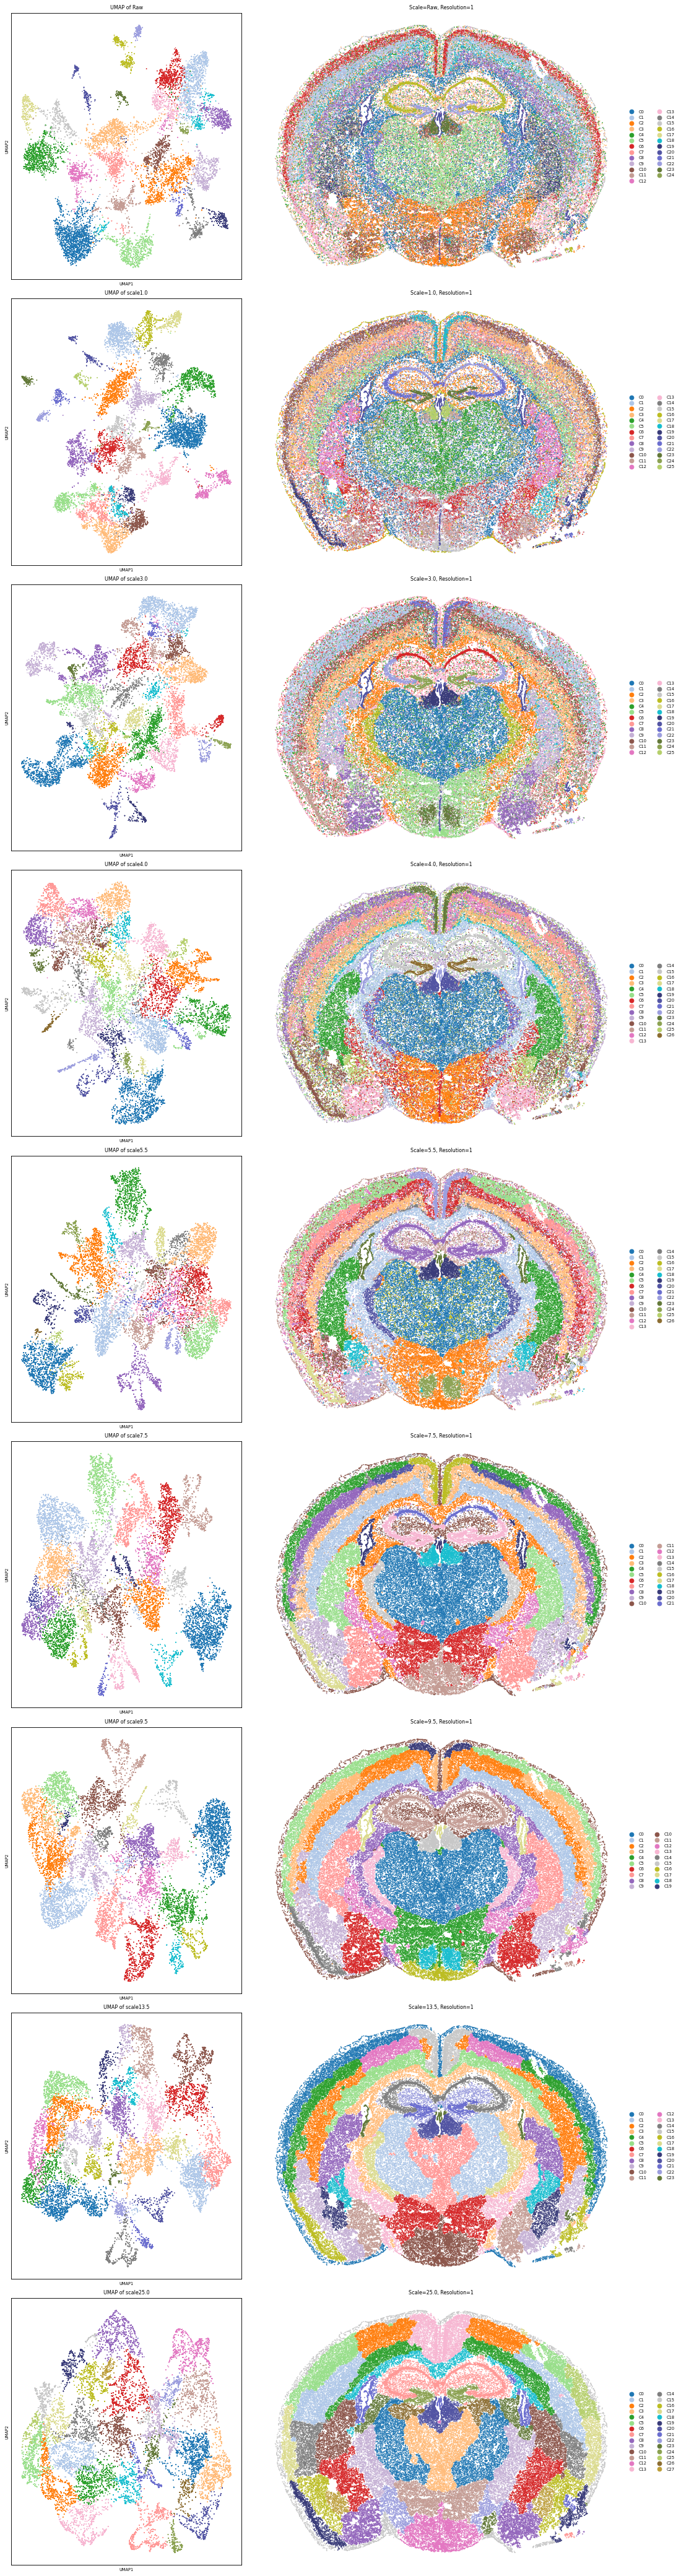

In [12]:
sz_analyzer.plot_multiscale_clusters(resolution=1, figsize=(14, 52), pt_size_scatter= 0.5, pt_size_umap=7)

Quantify the contributions of spatial proximity and transcriptomic similarity to clustering outcomes across different scales.

Median similarities:  4.999999995701405
Time taken to construct expr_knn: 7.7937 seconds


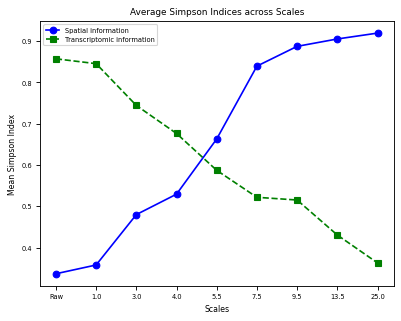

In [13]:
sz_analyzer.plot_simpson()

The `sz_analyzer.adata` object is an AnnData instance that is compatible with the Python ecosystem for scRNA-seq and ST data, including packages such as **scanpy** and **squidpy**. Users can therefore directly leverage these packages for further downstream analysis and visualization.

In [14]:
sz_analyzer.adata.write(save_path + runLabel + '_SpatialZoomer.h5ad')

### Results in the `save_path` folder

The following output files are generated and saved in the `save_path` directory:

- `<runLabel>_SpatialZoomer.h5ad`: The core AnnData object containing all multi-scale clustering results, recommended for downstream analyses.

- `<runLabel>_transformed_signals.h5`: Stores the multi-scale features extracted by the spectral graph filter bank.  

  Dimensions: *cells × cell programs × candidate scales*.  

- `Typical_scales.pdf`: Visualization of critical scale selection, generated by `identify_typical_scales()`.  

- `Typical_scales.csv`: Data frame recording the selected critical scales.  

- `<runLabel>_object_kmeans_<critical scale>.h5ad`: A series of AnnData objects storing the K-Means clustering results of metacells at specific critical scales.

  These intermediate results can be further refined by applying the Leiden algorithm, where adjusting the clustering resolution allows generation of the final clustering results.

- `Average_Simpson_Indices_across_Scales.pdf`: Output of `plot_simpson()`, which quantifies the contributions of spatial proximity and transcriptomic similarity to clustering results across scales.  

### 4. Scale-to-distance mapping

After running SpatialZoomer, `sz.mapping_scale_to_distance()` can be used to estimate the effective physical range corresponding to each scale. The resulting distances use the same units as `adata.obsm['spatial']`.

The function summarizes how spatial signals diffuse with distance and generates heatmaps for all cells and three cell-density groups: Low (lowest 10%), Medium (middle 80%), and High (highest 10%).

Results are saved in the `<out_dir>/scale_to_distance_mapping/` folder.

Calculate density
Using percentile: 10 (q10=1.00, q90=5.00)
Density_group
Medium    56975
High      15698
Low       10873
Name: count, dtype: int64


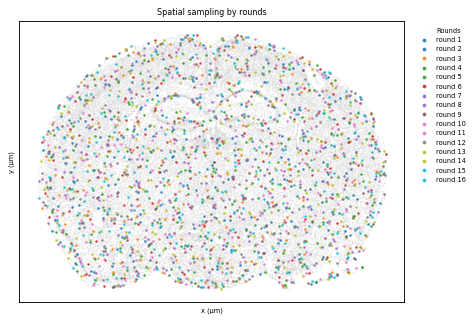

Computing overall heatmap (all 2000 seeds)...
Computing heatmap for group Low (314 seeds)...
Computing heatmap for group Medium (1270 seeds)...
Computing heatmap for group High (416 seeds)...
[Saved] All group data -> ./Outputs/Vizgen_MERFISH_Brain_Slice2_Replicate1_SpatialZoomer/scale_to_distance_mapping\heatmap_by_groups/H_matrix_All.csv, E95_distance_All.csv
[Saved] Low group data -> ./Outputs/Vizgen_MERFISH_Brain_Slice2_Replicate1_SpatialZoomer/scale_to_distance_mapping\heatmap_by_groups/H_matrix_Low.csv, E95_distance_Low.csv
[Saved] Medium group data -> ./Outputs/Vizgen_MERFISH_Brain_Slice2_Replicate1_SpatialZoomer/scale_to_distance_mapping\heatmap_by_groups/H_matrix_Medium.csv, E95_distance_Medium.csv
[Saved] High group data -> ./Outputs/Vizgen_MERFISH_Brain_Slice2_Replicate1_SpatialZoomer/scale_to_distance_mapping\heatmap_by_groups/H_matrix_High.csv, E95_distance_High.csv
[Saved] PDF -> ./Outputs/Vizgen_MERFISH_Brain_Slice2_Replicate1_SpatialZoomer/scale_to_distance_mapping\Heat

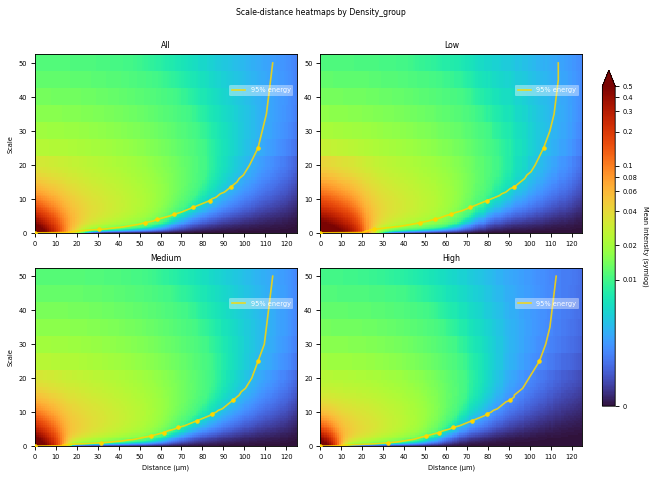

Time taken to perform physical distance analysis: 92.3414 seconds


In [ ]:
# Run scale-to-distance mapping.
# The spatial KNN graph is read from adata.obsp["spatial_knn"].
# When typical_scales=None, typical scales are inferred from the "X_umap_scale*" keys in adata.obsm.
out = sz.mapping_scale_to_distance(
    adata=sz_analyzer.adata,
    out_dir=save_path,
    run_label=runLabel,
    typical_scales=None,        # auto-extract typical scales from obsm (X_umap_scale*)
    plot_typical_scales=True,   # mark typical scales on the heatmap
    normalize_rows=False,       # Preserve the original scale-dependent intensities
    show=True,                  # Display the figures in the notebook
    dpi=use_dpi,
)